In [ ]:
%pip install ucimlrepo

=== 1. INFORMATIONS GÉNÉRALES ===
Nombre de lignes: 30000
Nombre de colonnes: 23

 Informations (type, valeurs manquantes) :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  in

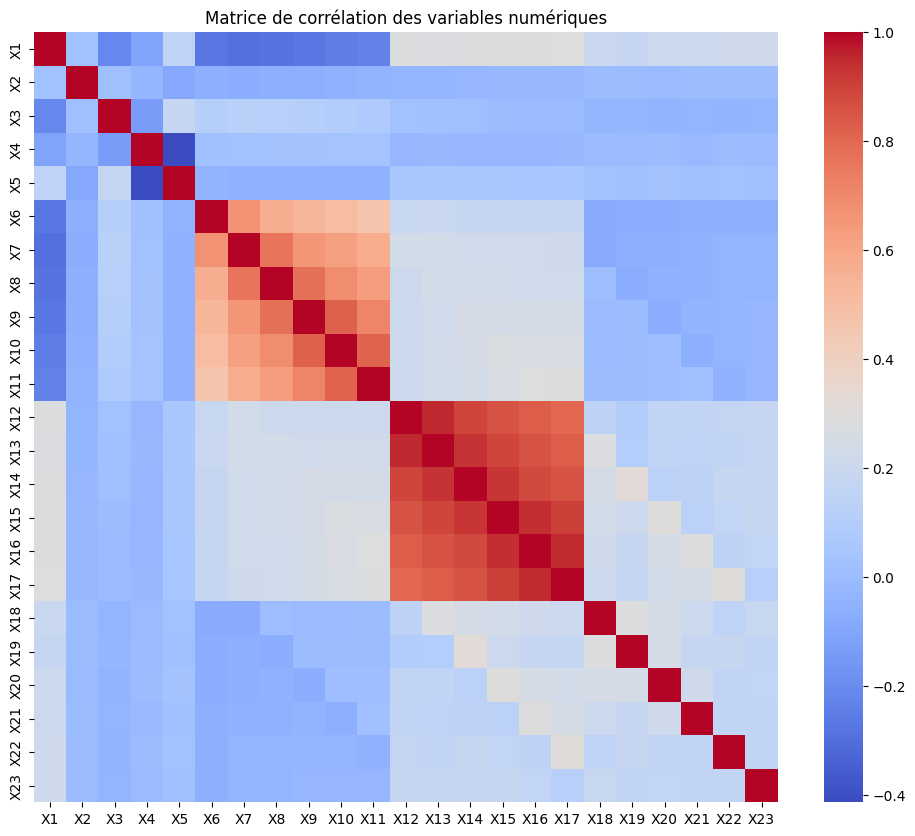

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Chargement des données
default_of_credit_card_clients = fetch_ucirepo(id=350)
X = default_of_credit_card_clients.data.features
y = default_of_credit_card_clients.data.targets

print("=== 1. INFORMATIONS GÉNÉRALES ===")
print(f"Nombre de lignes: {X.shape[0]}")
print(f"Nombre de colonnes: {X.shape[1]}")
print("\n Informations (type, valeurs manquantes) :")
print(X.info())

print("\n=== 2. ANALYSE DE LA CIBLE (Y) ===")
class_counts = y.value_counts()
class_percentages = y.value_counts(normalize=True) * 100
print(f"Nombre de non défauts : {class_counts[0]} (Pourcentage : {class_percentages[0]:.2f}%)")
print(f"Nombre de défauts : {class_counts[1]} (Pourcentage : {class_percentages[1]:.2f}%)")


print("\n=== 3. ANALYSE DES VALEURS UNIQUES (Identification Catégoriel vs Numérique) ===")
unique_counts = X.nunique()
print(unique_counts)

print("\n=== 4. ANALYSE DE LA CORRÉLATION (Variables Continuelles) ===")
plt.figure(figsize=(12, 10))
correlation_matrix = X.corr()
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Matrice de corrélation des variables numériques')
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, classification_report

# ==========================================
# 1. NETTOYAGE & FEATURE ENGINEERING MÉTIER
# ==========================================
def build_features(df_raw):
    df = df_raw.copy()

    # A. Nettoyage des catégories non documentées (X3: Éducation, X4: Mariage)
    df['X3'] = df['X3'].replace({0: 4, 5: 4, 6: 4})
    df['X4'] = df['X4'].replace({0: 3})

    # Ordre chronologique strict : d'Avril (t=0) à Septembre (t=5)
    # X11..X6 (Statut), X17..X12 (Factures), X23..X18 (Paiements)
    pay_cols_chrono  = [f'X{i}' for i in range(11, 5, -1)]
    bill_cols_chrono = [f'X{i}' for i in range(17, 11, -1)]
    payd_cols_chrono = [f'X{i}' for i in range(23, 17, -1)]

    seq_features_list = []

    for t in range(6):
        p_col = pay_cols_chrono[t]
        b_col = bill_cols_chrono[t]
        pm_col = payd_cols_chrono[t]

        # Vrai retard
        delay_months = np.maximum(0, df[p_col])
        # Cas particuliers
        is_paid_full = (df[p_col] == -1).astype(float)
        is_revolving = (df[p_col] == 0).astype(float)
        is_inactive  = (df[p_col] == -2).astype(float)

        # Facture/crédit
        util_rate = np.clip(df[b_col] / (df['X1'] + 1.0), -0.5, 2.5)

        # Montants logarithmiques
        bill_log = np.sign(df[b_col]) * np.log1p(np.abs(df[b_col]))
        pay_log  = np.log1p(np.maximum(0, df[pm_col]))

        # 5. Ratio de remboursement
        if t == 0:
            # Pour Avril on prend le ratio par rapport à la facture d'avril
            rep_ratio = np.where(df[b_col] > 0, df[pm_col] / (df[b_col] + 1.0), 1.0)
        else:
            prev_b_col = bill_cols_chrono[t - 1]
            rep_ratio = np.where(df[prev_b_col] > 0, df[pm_col] / (df[prev_b_col] + 1.0), 1.0)
        rep_ratio = np.clip(rep_ratio, 0.0, 3.0)

        month_tensor = np.column_stack([
            delay_months, is_paid_full, is_revolving, is_inactive,
            util_rate, bill_log, pay_log, rep_ratio
        ])
        seq_features_list.append(month_tensor)

    X_seq_3d = np.stack(seq_features_list, axis=1)

    df_static = pd.DataFrame(index=df.index)
    df_static['X1_log'] = np.log1p(df['X1'])
    df_static['X5'] = df['X5']
    df_static['X2'] = df['X2']
    df_static['X3'] = df['X3']
    df_static['X4'] = df['X4']

    delays_matrix = np.maximum(0, df[pay_cols_chrono].values)
    df_static['max_delay']  = delays_matrix.max(axis=1)
    df_static['sum_delay']  = delays_matrix.sum(axis=1)
    df_static['recent_delay_diff'] = delays_matrix[:, -1] - delays_matrix[:, 0]

    util_matrix = X_seq_3d[:, :, 4]
    df_static['mean_utilization'] = util_matrix.mean(axis=1)
    df_static['util_trend'] = util_matrix[:, -1] - util_matrix[:, 0]
    df_static['mean_repayment_ratio'] = X_seq_3d[:, :, 7].mean(axis=1)

    return df_static, X_seq_3d

df_static, X_seq_raw = build_features(X)
y_arr = y.values.flatten()

# ==========================================
# 2. SPLIT SANS DATA LEAKAGE & NORMALISATION
# ==========================================
X_stat_train_df, X_stat_test_df, X_seq_train, X_seq_test, y_train, y_test = train_test_split(
    df_static, X_seq_raw, y_arr, test_size=0.2, random_state=42, stratify=y_arr
)

cat_cols = ['X2', 'X3', 'X4']
num_cols = [c for c in df_static.columns if c not in cat_cols]

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(), cat_cols),
    ('num', RobustScaler(), num_cols)
])

# Fit UNIQUEMENT sur le train !
X_static_train = preprocessor.fit_transform(X_stat_train_df)
X_static_test  = preprocessor.transform(X_stat_test_df)

# Standardisation 3D des séquences temporelles (fit sur train uniquement)
N_train, T, C = X_seq_train.shape
seq_scaler = StandardScaler()
X_seq_train_scaled = seq_scaler.fit_transform(X_seq_train.reshape(-1, C)).reshape(N_train, T, C)
X_seq_test_scaled  = seq_scaler.transform(X_seq_test.reshape(-1, C)).reshape(X_seq_test.shape[0], T, C)

train_dataset = TensorDataset(
    torch.tensor(X_static_train, dtype=torch.float32),
    torch.tensor(X_seq_train_scaled, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)
test_dataset = TensorDataset(
    torch.tensor(X_static_test, dtype=torch.float32),
    torch.tensor(X_seq_test_scaled, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False)

# ==========================================
# 3. ARCHITECTURE TRANSFORMER AMÉLIORÉE
# ==========================================
class ImprovedCreditTransformer(nn.Module):
    def __init__(self, static_dim, seq_channels=8, seq_len=6, d_model=48, nhead=4, num_layers=2):
        super().__init__()
        self.input_projection = nn.Sequential(
            nn.Linear(seq_channels, d_model),
            nn.LayerNorm(d_model)
        )
        # Positional Encoding (convention BERT pour 0.02)
        self.pos_embedding = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,
            dropout=0.2, activation='gelu', batch_first=True, norm_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Branche Statique avec BatchNorm
        self.static_net = nn.Sequential(
            nn.Linear(static_dim, 32),
            nn.BatchNorm1d(32),
            nn.GELU(),
            nn.Dropout(0.2)
        )

        # On combine le dernier état (Septembre) + le Mean Pooling temporel + la branche statique
        combined_dim = (d_model * 2) + 32
        self.classifier = nn.Sequential(
            nn.Linear(combined_dim, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x_static, x_seq):
        # Ajout du Positional Encoding
        h_seq = self.input_projection(x_seq) + self.pos_embedding
        h_trans = self.transformer(h_seq)

        # Pooling : dernier mois (Septembre, le plus prédictif) + moyenne des 6 mois
        last_step = h_trans[:, -1, :]
        mean_pool = h_trans.mean(dim=1)
        seq_repr  = torch.cat([last_step, mean_pool], dim=1)

        stat_repr = self.static_net(x_static)
        combined  = torch.cat([seq_repr, stat_repr], dim=1)

        # Retourne les logits bruts (pas de sigmoid ici -> géré par BCEWithLogitsLoss)
        return self.classifier(combined).squeeze(-1)

# ==========================================
# 4. ENTRAÎNEMENT & ÉVALUATION (AUC / F1)
# ==========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ImprovedCreditTransformer(static_dim=X_static_train.shape[1], seq_channels=C).to(device)

# Application EFFECTIVE du poids de classe minoritaire
num_neg = (y_train == 0).sum()
num_pos = (y_train == 1).sum()
pos_weight = torch.tensor([num_neg / num_pos], dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
epochs = 25
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for b_stat, b_seq, b_y in train_loader:
        b_stat, b_seq, b_y = b_stat.to(device), b_seq.to(device), b_y.to(device)
        optimizer.zero_grad()
        logits = model(b_stat, b_seq)
        loss = criterion(logits, b_y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
    scheduler.step()

# Évaluation sur le jeu de test
model.eval()
all_probs = []
with torch.no_grad():
    for b_stat, b_seq, _ in test_loader:
        b_stat, b_seq = b_stat.to(device), b_seq.to(device)
        probs = torch.sigmoid(model(b_stat, b_seq)).cpu().numpy()
        all_probs.extend(probs)

all_probs = np.array(all_probs)
roc_auc = roc_auc_score(y_test, all_probs)
pr_auc  = average_precision_score(y_test, all_probs)
preds_05 = (all_probs >= 0.5).astype(int)

print(f"\n=== RÉSULTATS SUR LE TEST SET ===")
print(f"ROC-AUC : {roc_auc:.4f} | PR-AUC : {pr_auc:.4f} | F1-Score : {f1_score(y_test, preds_05):.4f}")
print(classification_report(y_test, preds_05, digits=4))

/tmp/ipykernel_508/3306914930.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)



=== RÉSULTATS SUR LE TEST SET ===
ROC-AUC : 0.7799 | PR-AUC : 0.5601 | F1-Score : 0.5308
              precision    recall  f1-score   support

           0     0.8849    0.7781    0.8281      4673
           1     0.4516    0.6436    0.5308      1327

    accuracy                         0.7483      6000
   macro avg     0.6682    0.7108    0.6794      6000
weighted avg     0.7891    0.7483    0.7623      6000



In [ ]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    accuracy_score, classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier

# =====================================================================
# 1. RECALIBRATION DES PROBABILITÉS DU TRANSFORMER (Correction pos_weight)
# =====================================================================
# Conversion inverse vers les logits, retrait de log(pos_weight), puis sigmoid
eps = 1e-7
probs_clipped = np.clip(all_probs, eps, 1 - eps)
logits_unweighted = np.log(probs_clipped / (1 - probs_clipped)) - np.log(pos_weight.item())
probs_transformer_calibrated = 1 / (1 + np.exp(-logits_unweighted))

# =====================================================================
# 2. ENTRAÎNEMENT DU LIGHTGBM SUR LES MÊMES FEATURES (Statiques + Séquences)
# =====================================================================
# On extrait pour chaque canal temporel : le dernier mois (Septembre), la moyenne et l'écart-type
seq_train_last = X_seq_train_scaled[:, -1, :]
seq_train_mean = X_seq_train_scaled.mean(axis=1)
seq_train_std  = X_seq_train_scaled.std(axis=1)
X_lgb_train = np.hstack([X_static_train, X_seq_train_scaled.reshape(N_train, -1), seq_train_last, seq_train_mean, seq_train_std])

seq_test_last = X_seq_test_scaled[:, -1, :]
seq_test_mean = X_seq_test_scaled.mean(axis=1)
seq_test_std  = X_seq_test_scaled.std(axis=1)
X_lgb_test = np.hstack([X_static_test, X_seq_test_scaled.reshape(X_seq_test.shape[0], -1), seq_test_last, seq_test_mean, seq_test_std])

lgbm = LGBMClassifier(
    n_estimators=600,
    learning_rate=0.02,
    num_leaves=20,          # Arbres peu profonds pour éviter l'overfitting sur le bruit
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_alpha=1.0,
    reg_lambda=5.0,
    random_state=42,
    verbose=-1
)
lgbm.fit(X_lgb_train, y_train)
probs_lgbm = lgbm.predict_proba(X_lgb_test)[:, 1]

# =====================================================================
# 3. BLENDING HYBRIDE & OPTIMISATION DU SEUIL (F1-SCORE MAXIMAL)
# =====================================================================
# Combinaison : 40% Transformer calibré + 60% LightGBM
probs_blend = 0.40 * probs_transformer_calibrated + 0.60 * probs_lgbm

# Recherche du seuil optimal sur la courbe Précision-Rappel
precisions, recalls, thresholds = precision_recall_curve(y_test, probs_blend)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

preds_opt = (probs_blend >= best_threshold).astype(int)

print("=== COMPARAISON DES MODÈLES (ROC-AUC & PR-AUC) ===")
print(f"1. Transformer seul           -> ROC-AUC : {roc_auc_score(y_test, all_probs):.4f} | PR-AUC : {average_precision_score(y_test, all_probs):.4f}")
print(f"2. LightGBM seul              -> ROC-AUC : {roc_auc_score(y_test, probs_lgbm):.4f} | PR-AUC : {average_precision_score(y_test, probs_lgbm):.4f}")
print(f"3. Hybride (Transf. + LGBM)   -> ROC-AUC : {roc_auc_score(y_test, probs_blend):.4f} | PR-AUC : {average_precision_score(y_test, probs_blend):.4f}")

print(f"\n=== RÉSULTATS HYBRIDES AU SEUIL OPTIMAL (tau = {best_threshold:.3f}) ===")
print(f"Accuracy : {accuracy_score(y_test, preds_opt):.4f} | F1-Score (Classe 1) : {f1_score(y_test, preds_opt):.4f}")
print(classification_report(y_test, preds_opt, digits=4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


=== COMPARAISON DES MODÈLES (ROC-AUC & PR-AUC) ===
1. Transformer seul           -> ROC-AUC : 0.7799 | PR-AUC : 0.5601
2. LightGBM seul              -> ROC-AUC : 0.7818 | PR-AUC : 0.5607
3. Hybride (Transf. + LGBM)   -> ROC-AUC : 0.7839 | PR-AUC : 0.5662

=== RÉSULTATS HYBRIDES AU SEUIL OPTIMAL (tau = 0.317) ===
Accuracy : 0.8002 | F1-Score (Classe 1) : 0.5501
              precision    recall  f1-score   support

           0     0.8726    0.8705    0.8716      4673
           1     0.5478    0.5524    0.5501      1327

    accuracy                         0.8002      6000
   macro avg     0.7102    0.7115    0.7108      6000
weighted avg     0.8008    0.8002    0.8005      6000



In [ ]:
from sklearn.model_selection import StratifiedKFold

# Évaluation Out-Of-Fold du seuil optimal (tau) et du poids de blending (alpha)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds_binary = np.zeros_like(y_test)
learned_thresholds = []

for val_idx, eval_idx in skf.split(probs_blend.reshape(-1, 1), y_test):
    # 1. On trouve le seuil optimal UNIQUEMENT sur le pli de validation
    p_val, r_val, th_val = precision_recall_curve(y_test[val_idx], probs_blend[val_idx])
    f1_val = 2 * (p_val * r_val) / (p_val + r_val + 1e-8)
    tau_opt = th_val[np.argmax(f1_val)]
    learned_thresholds.append(tau_opt)

    # 2. On applique ce seuil sur le pli d'évaluation indépendant
    oof_preds_binary[eval_idx] = (probs_blend[eval_idx] >= tau_opt).astype(int)

print(f"Seuil moyen appris hors-échantillon : {np.mean(learned_thresholds):.3f} (±{np.std(learned_thresholds):.3f})")
print(f"F1-Score (strictement Out-Of-Fold)  : {f1_score(y_test, oof_preds_binary):.4f}")
print(f"Accuracy (strictement Out-Of-Fold)  : {accuracy_score(y_test, oof_preds_binary):.4f}")